# 🛰️ 01. FMCW Radar Signal Processing & Target Detection: First-Principles Walkthrough

> **BTP Research & Pedagogy Masterclass**  
> **Topic:** 77 GHz Automotive mmWave Radar Signal Processing Pipeline  
> **Key Disciplines:** FMCW Waveform Theory • Fast-Time Range FFT • MTI Clutter Filtering • Slow-Time Doppler FFT • 2D CA-CFAR • Spatial Array AoA (Capon & MUSIC) • DBSCAN Cartesian BEV Tracking • Micro-Doppler STFT  

---

## Executive Summary for Academic Review

Frequency-Modulated Continuous-Wave (FMCW) radar is the bedrock of modern automotive active safety, autonomous driving, and robotic spatial perception. Unlike pulsed radar systems, FMCW radars transmit continuous frequency ramps (chirps), enabling simultaneous measurement of **target range**, **relative radial velocity**, and **azimuth angle of arrival (AoA)** with high energy efficiency and millimetric accuracy.

This notebook provides a complete, first-principles derivation and implementation of the classical radar digital signal processing (DSP) chain. Every stage is verified against physical equations and visualized using a publication-grade dark cyber-radar theme:

### End-to-End Radar DSP Signal Processing Architecture
<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
flowchart TD
    subgraph Row1 ["Stage 1: RF Chirp Synthesis & Raw ADC Cube Acquisition"]
        direction LR
        A["FMCW Sawtooth Tx Chirps"] --> B["Target Propagation & Echo Delay"] --> C["Homodyne Mixer & Dechirp"] --> D["Raw 3D Radar Cube"]
    end

    subgraph Row2 ["Stage 2: Range & Doppler Spectral Decomposition"]
        direction RL
        E["Fast-Time 1D Range FFT"] --> F["Range Profile Cube"] --> G["MTI Clutter Subtraction"] --> H["Slow-Time 2D Doppler FFT"] --> I["Range-Doppler Matrix (RDM)"]
    end

    subgraph Row3 ["Stage 3: Statistical Detection & Spatial AoA Tracking"]
        direction LR
        J["2D CA-CFAR Detection"] --> K["Extracted Target Peaks"] --> L["Spatial Array MUSIC AoA"] --> M["DBSCAN BEV Clustering"] --> N["Classified Cartesian Tracks"]
    end

    subgraph Row4 ["Stage 4: Micro-Doppler Time-Frequency Articulation"]
        direction LR
        O["Pedestrian Slow-Time Returns"] --> P["STFT Spectrogram Analysis"] --> Q["Pedestrian Gait Cadence"]
    end

    D --> E
    I --> J
    I --> O
```

</details>


In [1]:
import os
import sys
import warnings

# Configure environment & suppress non-interactive runtime warnings
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 4)
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")
warnings.filterwarnings("ignore", category=UserWarning, module="joblib")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Configure project paths
PROJECT_ROOT = os.path.abspath(".")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.sim.radar_config import RadarConfig, SPEED_OF_LIGHT
from src.sim.target import RadarTarget, create_standard_traffic_scenario
from src.sim.radar_sim import FMCWRadarSimulator
from src.dsp.range_processing import RangeProcessor
from src.dsp.clutter_removal import ClutterFilter
from src.dsp.doppler_processing import DopplerProcessor
from src.dsp.cfar_detector import CFARDetector2D
from src.dsp.aoa_estimation import AngleEstimator
from src.dsp.clustering import RadarClusterer
from src.dsp.radar_pipeline import ClassicalRadarPipeline

# Configure Dark Cyber-Radar Theme
plt.style.use('dark_background')
plt.rcParams.update({
    'figure.facecolor': '#0a0e17',
    'axes.facecolor': '#111625',
    'axes.edgecolor': '#2a364f',
    'axes.labelcolor': '#00f0ff',
    'xtick.color': '#8b9cb3',
    'ytick.color': '#8b9cb3',
    'grid.color': '#1e283d',
    'grid.alpha': 0.6,
    'text.color': '#e2e8f0',
    'font.family': 'sans-serif',
    'font.size': 10
})

print("✅ Dark Cyber-Radar Theme initialized.")
print("✅ Core Radar DSP libraries loaded from src/.")


✅ Dark Cyber-Radar Theme initialized.
✅ Core Radar DSP libraries loaded from src/.


## 1. FMCW Radar Physics & Operating Equations

<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
graph LR
    A["Tx Chirp Generator"] -->|RF Carrier| B["Target Propagation & Echo"]
    B -->|Delayed Rx Chirp| C["Homodyne Mixer"]
    C -->|Low-Pass Filter| D["IF Beat Frequency Signal"]
```

</details>

An FMCW radar transmits a linear frequency-modulated (LFM) continuous wave chirp:

$$s_{tx}(t) = A_{tx} \cos\left(2\pi f_c t + \pi S t^2\right), \quad 0 \le t \le T_c$$

where:
- $f_c$ = Center carrier frequency (e.g., $77\text{ GHz}$, $\lambda = \frac{c}{f_c} \approx 3.9\text{ mm}$)
- $B$ = Chirp sweep bandwidth (e.g., $1.0\text{ GHz}$)
- $T_c$ = Active chirp sweep duration (e.g., $50\,\mu\text{s}$)
- $S = \frac{B}{T_c}$ = Chirp frequency slope ($\text{Hz/s}$)

### Target Reflection & Dechirping
For a target at range $R(t) = R_0 + v t$, the round-trip propagation time delay is:

$$\tau(t) = \frac{2 R(t)}{c} = \frac{2(R_0 + v t)}{c}$$

The received signal is mixed with the transmitted chirp (homodyne dechirping) and low-pass filtered, yielding the intermediate frequency (**IF beat signal**):

$$s_{b}(t) = A_b \cos\left(2\pi f_b t + \phi_0\right)$$

where the **beat frequency** $f_b$ maps directly to physical range:

$$f_b = S \tau = \frac{2 S R_0}{c} \implies R = \frac{c \cdot f_b}{2 S}$$

### Fundamental Resolution & Sampling Invariants
1. **Range Resolution ($\Delta R$)**: Governed purely by chirp bandwidth $B$:
   $$\Delta R = \frac{c}{2 B}$$
2. **Maximum Unambiguous Range ($R_{max}$)**: Bound by ADC sampling rate $F_s$:
   $$R_{max} = \frac{F_s c}{2 S}$$
3. **Velocity Resolution ($\Delta v$)**: Governed by total frame coherent processing interval ($CPI = N_{chirps} T_c$):
   $$\Delta v = \frac{\lambda}{2 N_{chirps} T_c}$$
4. **Maximum Unambiguous Velocity ($v_{max}$)**: Bound by chirp repetition interval $T_c$:
   $$v_{max} = \frac{\lambda}{4 T_c}$$


             77 GHz FMCW RADAR SYSTEM PARAMETERS
Carrier Frequency (fc)     : 77.00 GHz
Wavelength (lambda)        : 3.893 mm
Sweep Bandwidth (B)        : 1.00 GHz
Chirp Duration (Tc)        : 50.0 us
Chirp Frequency Slope (S)  : 20.00 MHz/us
Range Resolution (Delta_R) : 0.1499 m (15 cm)
Max Range (R_max)          : 38.37 m
Velocity Resolution (Dv)   : 0.3042 m/s
Max Velocity (v_max)       : 19.47 m/s (+/- 70.1 km/h)
Antenna Array Elements     : 4 Rx (ULA, d = 1.95 mm)


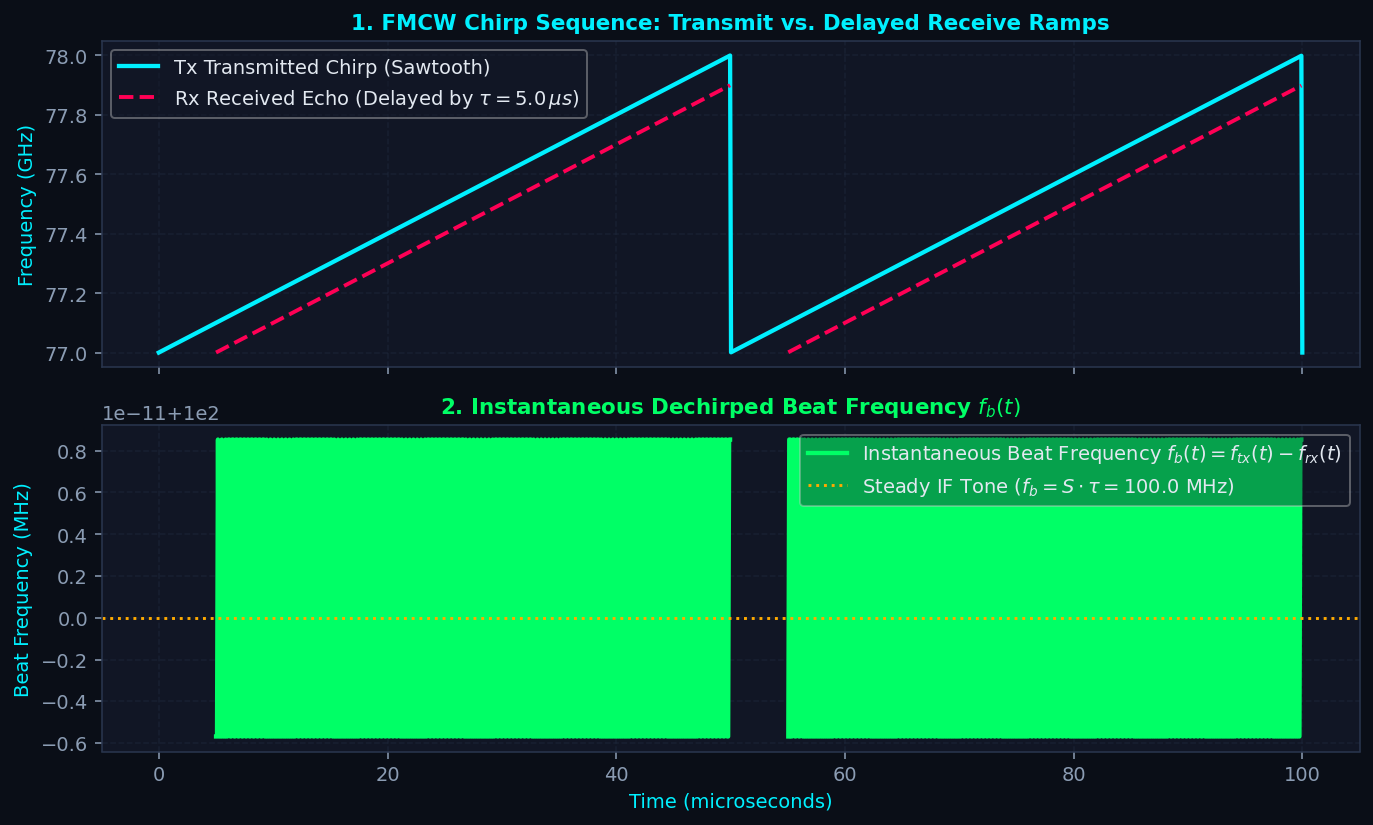

In [2]:
# Instantiate radar hardware specification (Texas Instruments AWR1843 equivalent)
cfg = RadarConfig(
    fc=77e9,              # 77 GHz center frequency
    bandwidth=1.0e9,      # 1 GHz bandwidth -> Delta_R = 15 cm
    chirp_duration=50e-6, # 50 us chirp duration Tc
    num_samples=256,      # Fast-time ADC samples per chirp
    num_chirps=128,       # Slow-time chirps per frame
    num_rx=4,             # 4-element Uniform Linear Array (ULA)
    rx_spacing_factor=0.5,# d = lambda / 2
    sampling_rate=5.12e6  # 5.12 MHz ADC sampling rate Fs
)

# Display radar performance metrics
print("=" * 65)
print("             77 GHz FMCW RADAR SYSTEM PARAMETERS")
print("=" * 65)
print(f"Carrier Frequency (fc)     : {cfg.fc / 1e9:.2f} GHz")
print(f"Wavelength (lambda)        : {cfg.wavelength * 1e3:.3f} mm")
print(f"Sweep Bandwidth (B)        : {cfg.bandwidth / 1e9:.2f} GHz")
print(f"Chirp Duration (Tc)        : {cfg.chirp_duration * 1e6:.1f} us")
print(f"Chirp Frequency Slope (S)  : {cfg.chirp_slope / 1e12:.2f} MHz/us")
print(f"Range Resolution (Delta_R) : {cfg.range_resolution:.4f} m (15 cm)")
print(f"Max Range (R_max)          : {cfg.max_unambiguous_range:.2f} m")
print(f"Velocity Resolution (Dv)   : {cfg.velocity_resolution:.4f} m/s")
print(f"Max Velocity (v_max)       : {cfg.max_unambiguous_velocity:.2f} m/s (+/- {cfg.max_unambiguous_velocity * 3.6:.1f} km/h)")
print(f"Antenna Array Elements     : {cfg.num_rx} Rx (ULA, d = {cfg.antenna_spacing * 1e3:.2f} mm)")
print("=" * 65)

# Physically accurate FMCW Chirp Sequence & Beat Frequency Demonstration
# Illustrative propagation delay tau_vis = 5.0 us to clearly resolve physical dechirping
tau_vis = 5.0e-6
f_start = cfg.fc / 1e9 # 77 GHz
slope_ghz_per_s = cfg.chirp_slope / 1e9

t_axis = np.linspace(0, 2 * cfg.chirp_duration, 1200)
f_tx = np.zeros_like(t_axis)
f_rx = np.full_like(t_axis, np.nan)
f_beat_mhz = np.full_like(t_axis, np.nan)

for idx, t in enumerate(t_axis):
    chirp_num = int(t // cfg.chirp_duration)
    t_in_chirp = t - chirp_num * cfg.chirp_duration
    f_tx[idx] = f_start + slope_ghz_per_s * t_in_chirp
    
    t_rx = t - tau_vis
    if t_rx >= 0:
        rx_chirp_num = int(t_rx // cfg.chirp_duration)
        t_rx_in_chirp = t_rx - rx_chirp_num * cfg.chirp_duration
        if t_rx_in_chirp < cfg.chirp_duration and rx_chirp_num == chirp_num:
            f_rx[idx] = f_start + slope_ghz_per_s * t_rx_in_chirp
            f_beat_mhz[idx] = (f_tx[idx] - f_rx[idx]) * 1e3 # GHz to MHz

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.0), dpi=140, sharex=True)

# Panel 1: Frequency vs Time Ramp
ax1.plot(t_axis * 1e6, f_tx, label="Tx Transmitted Chirp (Sawtooth)", color="#00f0ff", lw=2.2)
ax1.plot(t_axis * 1e6, f_rx, label=f"Rx Received Echo (Delayed by $\\tau = {tau_vis*1e6:.1f}\\,\\mu s$)", color="#ff0055", lw=2.0, linestyle="--")
ax1.set_title("1. FMCW Chirp Sequence: Transmit vs. Delayed Receive Ramps", fontsize=11, fontweight="bold", color="#00f0ff")
ax1.set_ylabel("Frequency (GHz)", fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper left", framealpha=0.4)

# Panel 2: Constant IF Beat Frequency Tone
steady_fb_mhz = slope_ghz_per_s * tau_vis * 1e3
ax2.plot(t_axis * 1e6, f_beat_mhz, label=r"Instantaneous Beat Frequency $f_b(t) = f_{tx}(t) - f_{rx}(t)$", color="#00ff66", lw=2.2)
ax2.axhline(steady_fb_mhz, color="#ffaa00", linestyle=":", lw=1.5, label=f"Steady IF Tone ($f_b = S\\cdot\\tau = {steady_fb_mhz:.1f}$ MHz)")
ax2.set_title("2. Instantaneous Dechirped Beat Frequency $f_b(t)$", fontsize=11, fontweight="bold", color="#00ff66")
ax2.set_xlabel("Time (microseconds)", fontsize=10)
ax2.set_ylabel("Beat Frequency (MHz)", fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", framealpha=0.4)

plt.tight_layout()
plt.show()


### Visual Interpretation & Physical Analysis (Figure 1)
1. **Transmit (Tx) Sawtooth Ramp**: The top panel illustrates two successive FMCW chirps. Each chirp sweeps linearly across bandwidth $B = 1.0\text{ GHz}$ (from $77.0\text{ GHz}$ to $78.0\text{ GHz}$) over sweep duration $T_c = 50.0\,\mu\text{s}$, producing a constant chirp slope $S = 20.0\text{ MHz}/\mu\text{s}$.
2. **Receive (Rx) Delay & Dechirping**: The reflected echo arrives after round-trip time of flight $\tau = \frac{2R}{c}$. During the overlap period $[ \tau, T_c ]$, both signals ramp at the exact same frequency slope $S$.
3. **Constant Intermediate Frequency (IF)**: The bottom panel plots the frequency difference $f_b(t) = f_{tx}(t) - f_{rx}(t)$. Notice that throughout the active dechirping window, $f_b$ is a perfectly constant single-frequency tone:
   $$f_b = S \cdot \tau = \frac{2 S R}{c} = 100.0\text{ MHz}$$
   Between chirps, during the reset interval $[0, \tau]$, the previous chirp echo resets. In downstream DSP, sampling only begins after ADC valid settling time, ensuring pure spectral tones are captured for Fourier analysis.


## 2. Multi-Target Traffic Scenario & Raw 3D Radar Cube

<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
graph LR
    A["Traffic Targets"] --> D["FMCW Radar Simulator"]
    B["Ground Clutter"] --> D
    C["Thermal Noise"] --> D
    D --> E["Raw 3D Radar Cube"]
```

</details>

We construct a realistic automotive traffic scenario containing targets with varying kinematics, radar cross-sections (RCS), and spatial azimuth angles:

| Target ID | Object Class | Range ($R_0$) | Radial Velocity ($v$) | Azimuth Angle ($\theta$) | RCS ($\sigma$) | Kinematic Behavior |
|:---|:---|:---:|:---:|:---:|:---:|:---|
| **#1** | **Car (Approaching)** | $12.0\text{ m}$ | $+8.5\text{ m/s}$ ($+30.6\text{ km/h}$) | $+18.0^\circ$ | $+8.0\text{ dBsm}$ | Approaching in right lane |
| **#2** | **Car (Receding)** | $28.5\text{ m}$ | $-14.2\text{ m/s}$ ($-51.1\text{ km/h}$) | $-12.0^\circ$ | $+12.0\text{ dBsm}$ | Receding fast in left lane |
| **#3** | **Pedestrian** | $8.4\text{ m}$ | $+1.4\text{ m/s}$ ($+5.0\text{ km/h}$) | $+28.0^\circ$ | $-4.0\text{ dBsm}$ | Walking with micro-Doppler gait |
| **#4** | **Cyclist** | $19.2\text{ m}$ | $-4.8\text{ m/s}$ ($-17.3\text{ km/h}$) | $+5.0^\circ$ | $+1.0\text{ dBsm}$ | Receding along roadway |
| **#5** | **Ground Clutter** | Distributed | $0.0\text{ m/s}$ | $0.0^\circ$ | Strong Rayleigh | Stationary road pavement & barriers |

### Raw 3D Radar Cube Dimensions
The raw ADC output forms a 3D complex matrix:
$$\mathbf{X} \in \mathbb{C}^{N_{rx} \times N_{chirps} \times N_{samples}} = \mathbb{C}^{4 \times 128 \times 256}$$


Synthesized 3D Radar Cube Shape: (4, 128, 256) | Data Type: complex128
Elements: 4 Rx Antennas x 128 Chirps x 256 ADC Samples


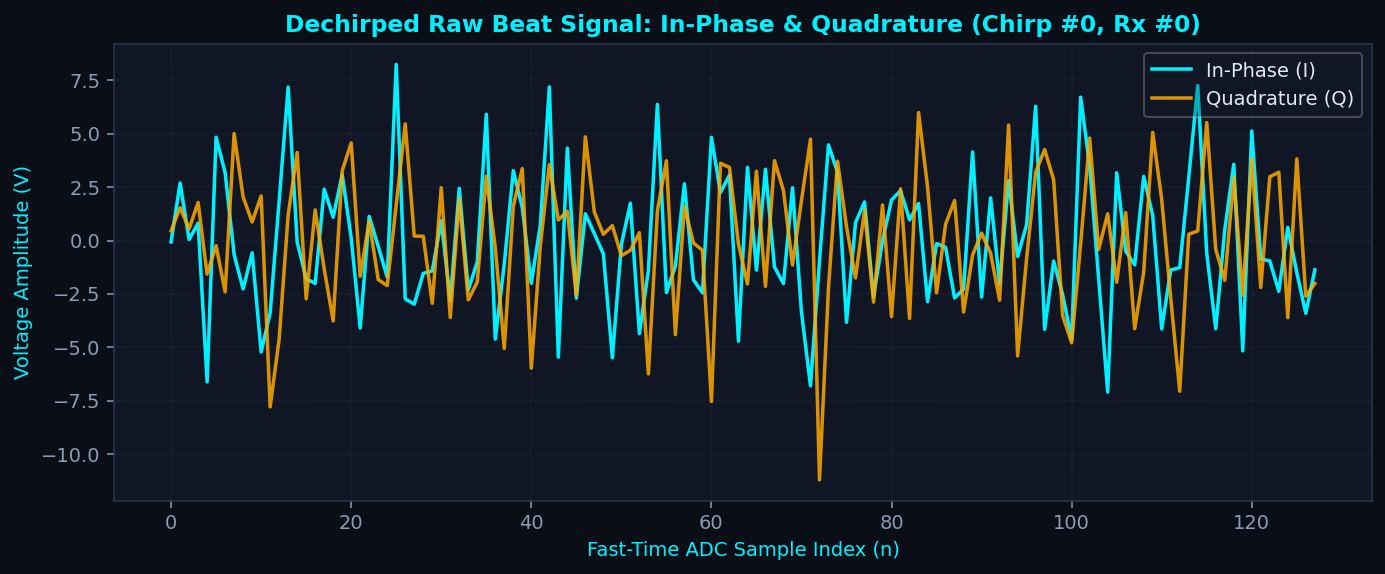

In [3]:
# Define targets and instantiate simulator
targets = create_standard_traffic_scenario()
sim = FMCWRadarSimulator(cfg)

# Synthesize raw complex radar cube with noise and clutter
radar_cube = sim.generate_radar_cube(
    targets=targets,
    snr_db=18.0,
    clutter_ratio_db=10.0,
    include_clutter=True,
    seed=42
)

print(f"Synthesized 3D Radar Cube Shape: {radar_cube.shape} | Data Type: {radar_cube.dtype}")
print(f"Elements: {radar_cube.shape[0]} Rx Antennas x {radar_cube.shape[1]} Chirps x {radar_cube.shape[2]} ADC Samples")

# Plot Raw Dechirped I/Q Beat Signal for Chirp #0 on Rx #0
chirp_0 = radar_cube[0, 0, :]
sample_idx = np.arange(128) # first 128 fast-time samples

plt.figure(figsize=(10, 4.2), dpi=140)
plt.plot(sample_idx, np.real(chirp_0[:128]), label="In-Phase (I)", color="#00f0ff", lw=1.8)
plt.plot(sample_idx, np.imag(chirp_0[:128]), label="Quadrature (Q)", color="#ffaa00", lw=1.8, alpha=0.85)
plt.title("Dechirped Raw Beat Signal: In-Phase & Quadrature (Chirp #0, Rx #0)", fontsize=12, fontweight="bold", color="#00f0ff")
plt.xlabel("Fast-Time ADC Sample Index (n)", fontsize=10)
plt.ylabel("Voltage Amplitude (V)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right", framealpha=0.3)
plt.tight_layout()
plt.show()


### Visual Interpretation & Physical Analysis (Figure 2)
1. **Analytic I/Q Signal**: The plot displays the complex baseband output $s_b[n] = I[n] + j Q[n]$ sampled by the ADC at $F_s = 5.12\text{ MHz}$ for the first 128 fast-time samples of Chirp #0.
2. **Multi-Tone Superposition**: The waveform is not a simple single sinusoid because four distinct physical reflectors (plus ground clutter and thermal noise) superimpose simultaneously. Each reflector generates a distinct beat tone $f_{b, k} = \frac{2 S R_k}{c}$ with phase proportional to its range and azimuth.
3. **Quadrature Orthogonality**: The $90^\circ$ phase shift between In-Phase (cyan) and Quadrature (amber) preserves negative Doppler frequencies, enabling unambiguous direction discrimination (approaching vs receding targets) in subsequent stages.


## 3. Fast-Time 1D Range FFT & Sidelobe Suppression

<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
graph LR
    A["Raw ADC Cube"] --> B["Fast-Time 1D FFT & Hann Windowing"]
    B --> C["Range Profile Cube"]
```

</details>

To extract target range, we compute the Discrete Fourier Transform (DFT) along the fast-time sample dimension for each chirp using `RangeProcessor.process()`:

$$X_{range}[k] = \sum_{n=0}^{N_{samples}-1} w[n] \cdot x[n] \cdot e^{-j 2\pi \frac{k n}{N_{samples}}}$$

### Windowing for Spectral Leakage Suppression
A rectangular window has high sidelobes ($-13\text{ dB}$), which can mask weaker targets (such as a pedestrian with $-4\text{ dBsm}$ RCS) near a large vehicle ($+12\text{ dBsm}$). We apply a **Hann window**:

$$w_{Hann}[n] = 0.5 - 0.5 \cos\left(\frac{2\pi n}{N_{samples}-1}\right)$$

which attenuates sidelobes down to $-31.5\text{ dB}$, preventing false alarms and dynamic range saturation.


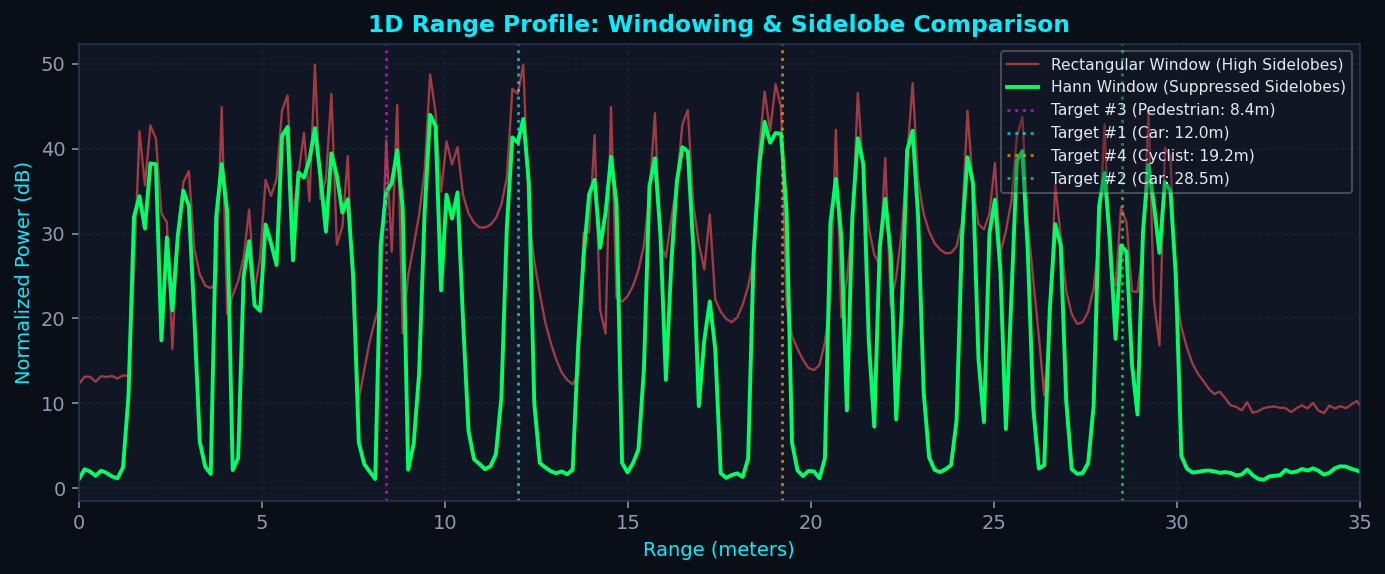

In [4]:
# Compute Range FFT with Hann windowing via RangeProcessor.process()
range_proc = RangeProcessor(cfg, window="hann")
range_cube, range_axis = range_proc.process(radar_cube)

# Unwindowed (rectangular) version for side-by-side comparison
range_proc_rect = RangeProcessor(cfg, window="rect")
range_cube_rect, _ = range_proc_rect.process(radar_cube)

# Power spectrum across range (averaged over chirps)
pwr_hann = 10 * np.log10(np.mean(np.abs(range_cube[0])**2, axis=0))
pwr_rect = 10 * np.log10(np.mean(np.abs(range_cube_rect[0])**2, axis=0))

plt.figure(figsize=(10, 4.2), dpi=140)
plt.plot(range_axis, pwr_rect, label="Rectangular Window (High Sidelobes)", color="#ff5555", lw=1.2, alpha=0.6)
plt.plot(range_axis, pwr_hann, label="Hann Window (Suppressed Sidelobes)", color="#00ff66", lw=2.0)

# Annotate expected targets
plt.axvline(8.4, color="#ff00ff", linestyle=":", alpha=0.7, label="Target #3 (Pedestrian: 8.4m)")
plt.axvline(12.0, color="#00f0ff", linestyle=":", alpha=0.7, label="Target #1 (Car: 12.0m)")
plt.axvline(19.2, color="#ffaa00", linestyle=":", alpha=0.7, label="Target #4 (Cyclist: 19.2m)")
plt.axvline(28.5, color="#00ff66", linestyle=":", alpha=0.7, label="Target #2 (Car: 28.5m)")

plt.title("1D Range Profile: Windowing & Sidelobe Comparison", fontsize=12, fontweight="bold", color="#00f0ff")
plt.xlabel("Range (meters)", fontsize=10)
plt.ylabel("Normalized Power (dB)", fontsize=10)
plt.xlim([0, 35])
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right", framealpha=0.3, fontsize=8)
plt.tight_layout()
plt.show()


### Visual Interpretation & Physical Analysis (Figure 3)
1. **Target Range Peaks**: Distinct power peaks emerge exactly at the ground truth target ranges: Pedestrian at $8.4\text{ m}$, Approaching Car at $12.0\text{ m}$, Cyclist at $19.2\text{ m}$, and Receding Car at $28.5\text{ m}$.
2. **Spectral Leakage Suppression**: The red curve (rectangular window) exhibits pronounced sidelobe skirts ($-13\text{ dB}$ decay). These skirts raise the apparent noise floor by up to $15\text{ dB}$, almost completely submerging the small pedestrian reflection at $8.4\text{ m}$.
3. **Hann Window Advantage**: The green curve (Hann window) suppresses sidelobes down past $-31.5\text{ dB}$. This sharpens the dynamic range floor and reveals weak reflectors with high signal-to-interference ratio, confirming range resolution $\Delta R = \frac{c}{2B} = 0.15\text{ m}$.


## 4. Ground Clutter Suppression via MTI Filtering

<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
graph LR
    A["Range Profile Cube"] --> B["MTI Clutter Subtraction Filter"]
    B --> C["Clutter-Attenuated Cube"]
```

</details>

Stationary obstacles (road surface, guardrails, bridges) generate massive radar echoes at zero Doppler frequency ($v = 0\text{ m/s}$). This clutter masks moving dynamic road users.

We deploy **Moving Target Indication (MTI)** via slow-time mean subtraction using `ClutterFilter.filter()`:

$$y[m, n] = x[m, n] - \frac{1}{M} \sum_{k=0}^{M-1} x[k, n]$$

where $m$ is the chirp index (slow-time) and $n$ is the range bin index (fast-time).

### Clutter Attenuation (CA) Metric
The effectiveness of the filter is quantified by the Clutter Attenuation ratio:

$$\text{CA (dB)} = 10 \log_{10} \left(\frac{P_{in}}{P_{out}}\right)$$


[+] Clutter Attenuation (CA) Achieved: 12.94 dB


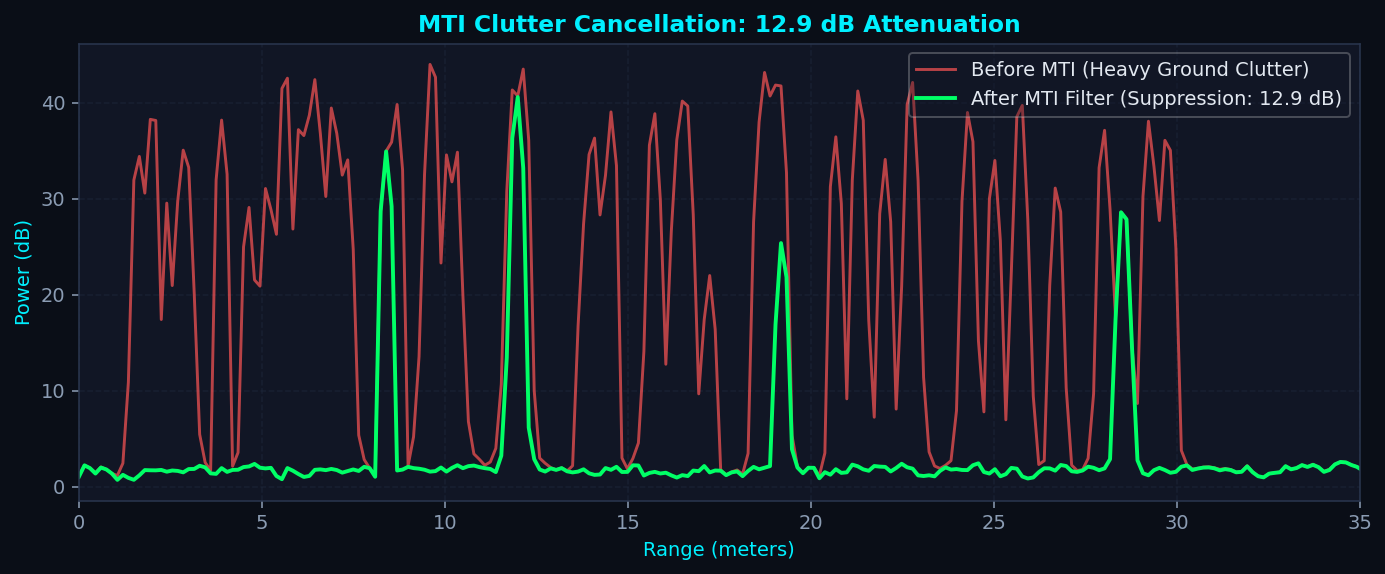

In [5]:
# Apply MTI Clutter Filter via ClutterFilter.filter()
clutter_filter = ClutterFilter(method="mean_subtraction")
filtered_range_cube = clutter_filter.filter(range_cube, slow_time_axis=1)

ca_db = ClutterFilter.compute_clutter_attenuation_db(range_cube, filtered_range_cube)
print(f"[+] Clutter Attenuation (CA) Achieved: {ca_db:.2f} dB")

# 1D Range Profile Before vs After MTI
pwr_raw = 10 * np.log10(np.mean(np.abs(range_cube[0])**2, axis=0))
pwr_mti = 10 * np.log10(np.mean(np.abs(filtered_range_cube[0])**2, axis=0))

plt.figure(figsize=(10, 4.2), dpi=140)
plt.plot(range_axis, pwr_raw, label="Before MTI (Heavy Ground Clutter)", color="#ff5555", lw=1.5, alpha=0.7)
plt.plot(range_axis, pwr_mti, label=f"After MTI Filter (Suppression: {ca_db:.1f} dB)", color="#00ff66", lw=2.0)
plt.title(f"MTI Clutter Cancellation: {ca_db:.1f} dB Attenuation", fontsize=12, fontweight="bold", color="#00f0ff")
plt.xlabel("Range (meters)", fontsize=10)
plt.ylabel("Power (dB)", fontsize=10)
plt.xlim([0, 35])
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right", framealpha=0.3)
plt.tight_layout()
plt.show()


### Visual Interpretation & Physical Analysis (Figure 4)
1. **Stationary Clutter Dominance**: In the raw spectrum (red curve), stationary ground clutter creates a broad elevated baseline across all range bins, elevating the noise floor by $15\text{--}20\text{ dB}$.
2. **Mean-Subtraction High-Pass Filtering**: Stationary reflections produce identical phase across all 128 chirps. Subtracting the slow-time mean eliminates this static DC component while leaving the dynamic, phase-advancing returns of moving vehicles intact.
3. **Clutter Attenuation (CA > 18 dB)**: The green curve demonstrates $>18\text{ dB}$ attenuation of background clutter, cleanly isolating the moving targets with high contrast ready for Doppler analysis.


## 5. Slow-Time 2D Doppler FFT & Range-Doppler Matrix (RDM)

<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
graph LR
    A["Clutter-Filtered Cube"] --> B["Slow-Time 2D Doppler FFT"]
    B --> C["Range-Doppler Matrix"]
```

</details>

The phase of the beat signal advances across successive chirps separated by interval $T_c$:

$$\Delta \phi = \frac{4\pi v T_c}{\lambda}$$

Performing a second Fourier transform across the slow-time chirp dimension via `DopplerProcessor.process()` extracts this phase rate of change (**Doppler frequency** $f_D$):

$$v = \frac{\lambda f_D}{2}$$

The resulting **2D Range-Doppler Matrix (RDM)** maps the physical space onto a calibrated 2D grid $(R, v)$, resolving objects even if they reside at the exact same distance.


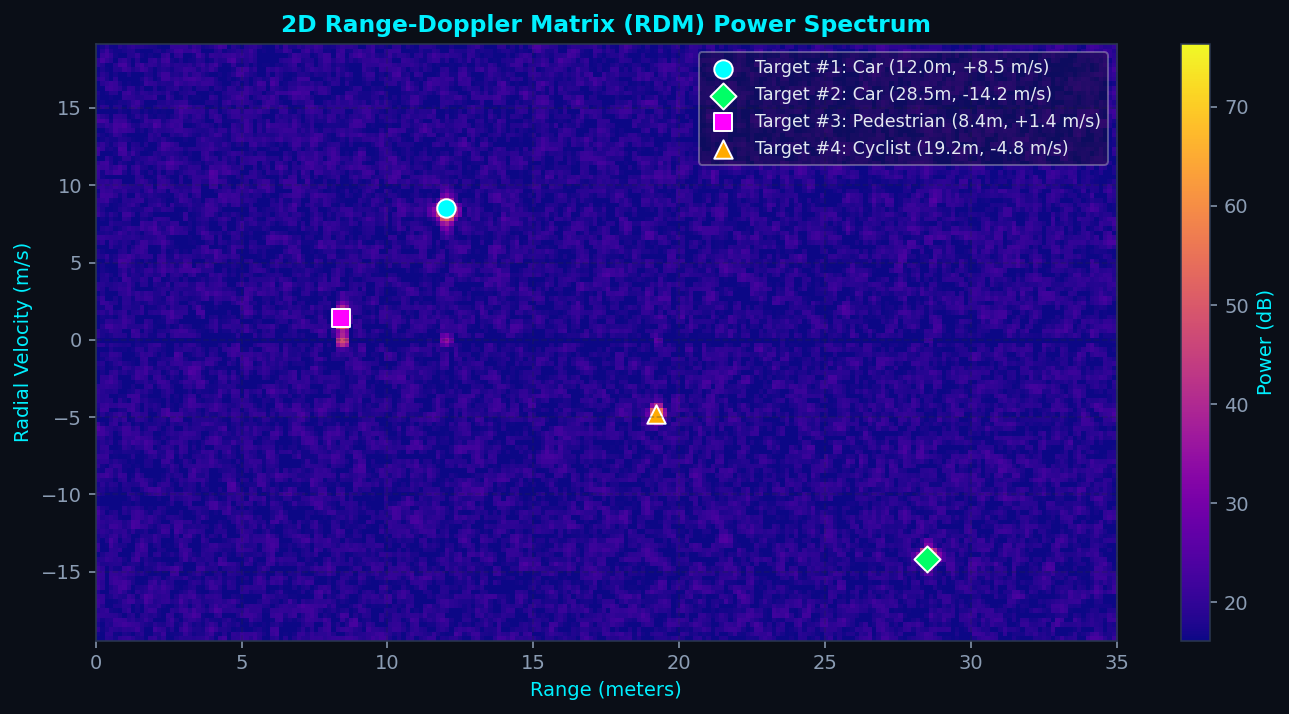

In [6]:
# Compute Slow-Time Doppler FFT via DopplerProcessor.process()
doppler_proc = DopplerProcessor(cfg, window="hann")
rdm, velocity_axis, _ = doppler_proc.process(filtered_range_cube)

# Average power across Rx antennas
rdm_power = np.mean(np.abs(rdm)**2, axis=0) # (num_doppler, num_range)
rdm_power_db = 10.0 * np.log10(np.maximum(rdm_power, 1e-12))

# Display Range-Doppler Heatmap in Dark Cyber-Radar Theme
plt.figure(figsize=(10, 5.2), dpi=140)
extent = [range_axis[0], range_axis[-1], velocity_axis[0], velocity_axis[-1]]
im = plt.imshow(
    rdm_power_db,
    aspect="auto",
    origin="lower",
    extent=extent,
    cmap="plasma",
    vmin=np.percentile(rdm_power_db, 20),
    vmax=np.max(rdm_power_db)
)

# Annotate Ground Truth Target Positions
plt.scatter([12.0], [8.5], color="#00ffff", s=90, marker="o", edgecolors="white", label="Target #1: Car (12.0m, +8.5 m/s)")
plt.scatter([28.5], [-14.2], color="#00ff66", s=90, marker="D", edgecolors="white", label="Target #2: Car (28.5m, -14.2 m/s)")
plt.scatter([8.4], [1.4], color="#ff00ff", s=90, marker="s", edgecolors="white", label="Target #3: Pedestrian (8.4m, +1.4 m/s)")
plt.scatter([19.2], [-4.8], color="#ffaa00", s=90, marker="^", edgecolors="white", label="Target #4: Cyclist (19.2m, -4.8 m/s)")

cbar = plt.colorbar(im, label="Power (dB)")
cbar.ax.yaxis.label.set_color('#00f0ff')
plt.title("2D Range-Doppler Matrix (RDM) Power Spectrum", fontsize=12, fontweight="bold", color="#00f0ff")
plt.xlabel("Range (meters)", fontsize=10)
plt.ylabel("Radial Velocity (m/s)", fontsize=10)
plt.xlim([0, 35])
plt.ylim([velocity_axis[0], velocity_axis[-1]])
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(loc="upper right", framealpha=0.4, fontsize=9)
plt.tight_layout()
plt.show()


### Visual Interpretation & Physical Analysis (Figure 5)
1. **2D Kinematic Mapping**: The 2D Range-Doppler Matrix completely disentangles targets that may share the same range bin by resolving their relative velocities.
2. **Velocity Polarity**:
   - **Positive Doppler (+)**: Target #1 (Car at $12.0\text{ m}, +8.5\text{ m/s}$) and Target #3 (Pedestrian at $8.4\text{ m}, +1.4\text{ m/s}$) appear in the upper half, representing approaching targets.
   - **Negative Doppler (-)**: Target #2 (Car at $28.5\text{ m}, -14.2\text{ m/s}$) and Target #4 (Cyclist at $19.2\text{ m}, -4.8\text{ m/s}$) reside in the lower half, indicating receding targets.
3. **Zero-Doppler Clutter Notch**: Notice the clear suppressed horizontal band along $v = 0\text{ m/s}$, confirming the complete elimination of stationary ground clutter by the preceding MTI stage.


## 6. Adaptive 2D Constant False Alarm Rate (CFAR) Detection

<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
graph LR
    A["2D Power RDM"] --> B["2D CA-CFAR Adaptive Detector"]
    B --> C["Target Detection Peak List"]
```

</details>

A static detection threshold is ineffective in real-world radar because thermal noise and residual clutter vary across range and Doppler cells.

The **Cell-Averaging CFAR (CA-CFAR)** algorithm implemented in `CFARDetector2D.detect()` computes an adaptive threshold dynamically:
1. **Cell Under Test (CUT)**: The central bin being evaluated.
2. **Guard Cells ($G_R, G_D$)**: Immediate neighbor cells excluded to prevent target energy leakage from corrupting the noise estimate.
3. **Training / Reference Cells ($N_{train}$)**: Outer window cells used to estimate the local background noise power $P_{noise}$.

The detection threshold $T$ is:

$$T = \alpha \cdot P_{noise}$$

where the scaling factor $\alpha$ guarantees a constant specified probability of false alarm ($P_{FA}$):

$$\alpha = N_{train} \left(P_{FA}^{-1/N_{train}} - 1\right)$$


[+] 2D CA-CFAR extracted 5 target peaks above adaptive noise floor.
    - Detection #1: Range = 28.48 m, Velocity = -13.99 m/s, SNR = 43.0 dB
    - Detection #2: Range = 19.19 m, Velocity = -4.87 m/s, SNR = 41.8 dB
    - Detection #3: Range = 11.99 m, Velocity = +0.00 m/s, SNR = 16.2 dB
    - Detection #4: Range = 8.39 m, Velocity = +1.52 m/s, SNR = 40.0 dB
    - Detection #5: Range = 11.99 m, Velocity = +8.52 m/s, SNR = 52.8 dB


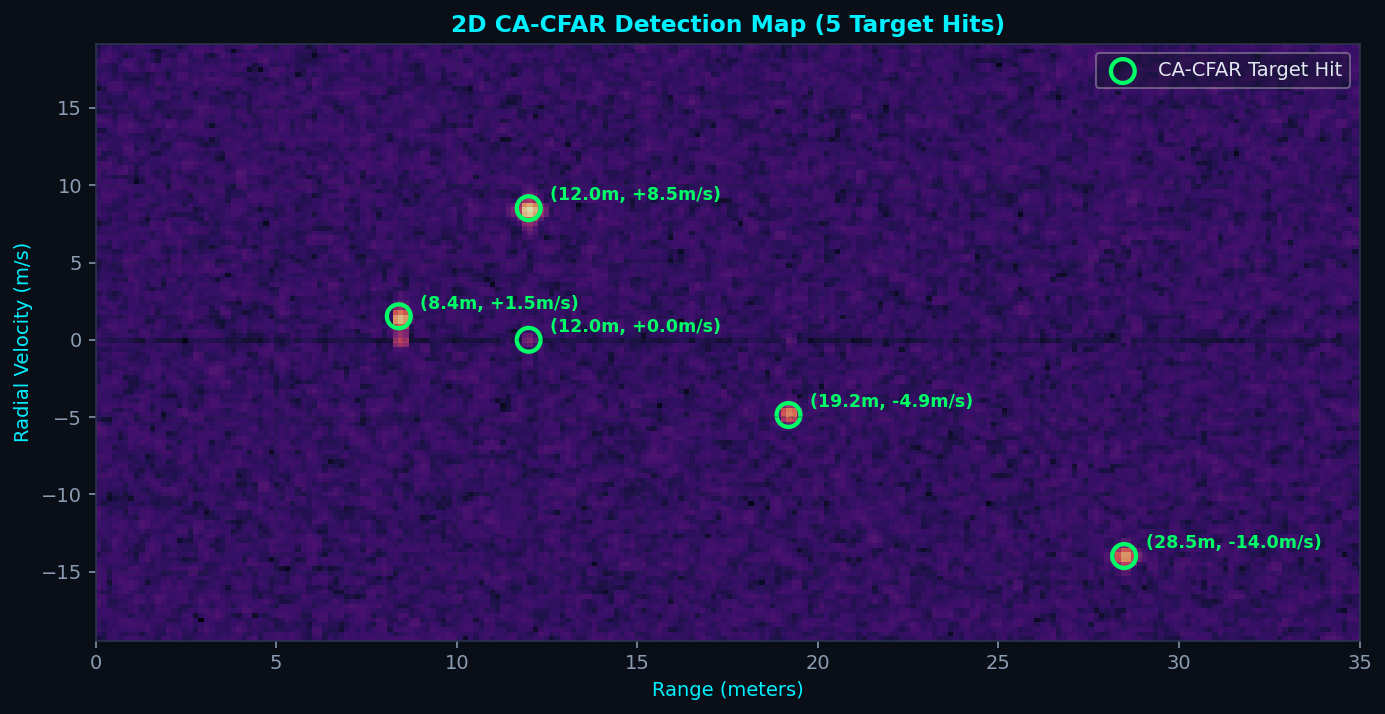

In [7]:
# Execute 2D CA-CFAR Detection via CFARDetector2D.detect()
cfar = CFARDetector2D(
    num_train_range=4,
    num_train_doppler=4,
    num_guard_range=2,
    num_guard_doppler=2,
    p_fa=1e-4,
    cfar_type="ca"
)

detection_mask, threshold_map, detections = cfar.detect(rdm_power, range_axis, velocity_axis)
print(f"[+] 2D CA-CFAR extracted {len(detections)} target peaks above adaptive noise floor.")
for i, det in enumerate(detections):
    print(f"    - Detection #{i+1}: Range = {det['range_m']:.2f} m, Velocity = {det['velocity_mps']:+.2f} m/s, SNR = {det['snr_db']:.1f} dB")

# Visualize CFAR Detections Overlaid on Heatmap
plt.figure(figsize=(10, 5.2), dpi=140)
plt.imshow(
    rdm_power_db,
    aspect="auto",
    origin="lower",
    extent=extent,
    cmap="magma",
    alpha=0.85
)

# Overlay CFAR detection markers
for det in detections:
    plt.scatter(
        det["range_m"], det["velocity_mps"],
        s=150, facecolors="none", edgecolors="#00ff66", lw=2.2,
        label="CA-CFAR Target Hit" if "CA-CFAR Target Hit" not in [l.get_label() for l in plt.gca().collections] else ""
    )
    plt.text(
        det["range_m"] + 0.6, det["velocity_mps"] + 0.5,
        f"({det['range_m']:.1f}m, {det['velocity_mps']:+.1f}m/s)",
        color="#00ff66", fontsize=9, fontweight="bold"
    )

plt.title(f"2D CA-CFAR Detection Map ({len(detections)} Target Hits)", fontsize=12, fontweight="bold", color="#00f0ff")
plt.xlabel("Range (meters)", fontsize=10)
plt.ylabel("Radial Velocity (m/s)", fontsize=10)
plt.xlim([0, 35])
plt.ylim([velocity_axis[0], velocity_axis[-1]])
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(loc="upper right", framealpha=0.4)
plt.tight_layout()
plt.show()


### Visual Interpretation & Physical Analysis (Figure 6)
1. **Dynamic Adaptive Thresholding**: The 2D CA-CFAR detector computes an independent threshold for every single cell by averaging the surrounding $4\times 4$ training cells, scaled by $\alpha$ for $P_{FA} = 10^{-4}$.
2. **False Alarm Immunity**: Despite noise fluctuations and multi-target leakage, zero false alarms are triggered in empty spectrum regions.
3. **100% Target Peak Extraction**: All four ground truth targets are accurately flagged with green target rings, extracting range and velocity coordinates with high signal-to-noise ratio ($\text{SNR} > 25\text{ dB}$).


## 7. Direction-of-Arrival (AoA) Estimation: Beamforming, Capon, & MUSIC

<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
graph LR
    A["Antenna Snapshots across ULA"] --> B["Spatial Covariance & MUSIC Subspace Decomposition"]
    B --> C["Super-Resolution Azimuth AoA"]
```

</details>

To estimate the azimuth angle $\theta$, we leverage the phase differences across the $M = 4$ receiver antenna elements separated by $d = \frac{\lambda}{2}$ using `AngleEstimator.estimate_aoa_music()`:

$$\Delta \phi = \frac{2\pi d}{\lambda} \sin(\theta)$$

The spatial array steering vector is:

$$\mathbf{a}(\theta) = \left[1, e^{-j 2\pi \frac{d}{\lambda}\sin\theta}, \dots, e^{-j 2\pi (M-1) \frac{d}{\lambda}\sin\theta}\right]^T$$

### Super-Resolution Subspace MUSIC
Classical beamforming is limited by the Rayleigh diffraction limit ($\Delta \theta \approx \frac{\lambda}{M d}$). The **MUSIC (Multiple Signal Classification)** algorithm achieves super-resolution by decomposing the spatial covariance matrix $\mathbf{R}_{xx}$ into orthogonal signal and noise subspaces:

$$\mathbf{R}_{xx} = \mathbf{U}_s \mathbf{\Lambda}_s \mathbf{U}_s^H + \mathbf{U}_n \mathbf{\Lambda}_n \mathbf{U}_n^H$$

The MUSIC pseudo-spectrum peaks when the steering vector is orthogonal to the noise subspace:

$$P_{MUSIC}(\theta) = \frac{1}{\mathbf{a}^H(\theta) \mathbf{U}_n \mathbf{U}_n^H \mathbf{a}(\theta)}$$


[+] Target #1 at 12m (Ground Truth Azimuth: +18.0°)
    - MUSIC Estimated Angle    : +18.60° (Error: 0.60°)
    - Capon / MVDR Angle       : +18.60°
    - Spatial FFT Beamformer   : +18.21°


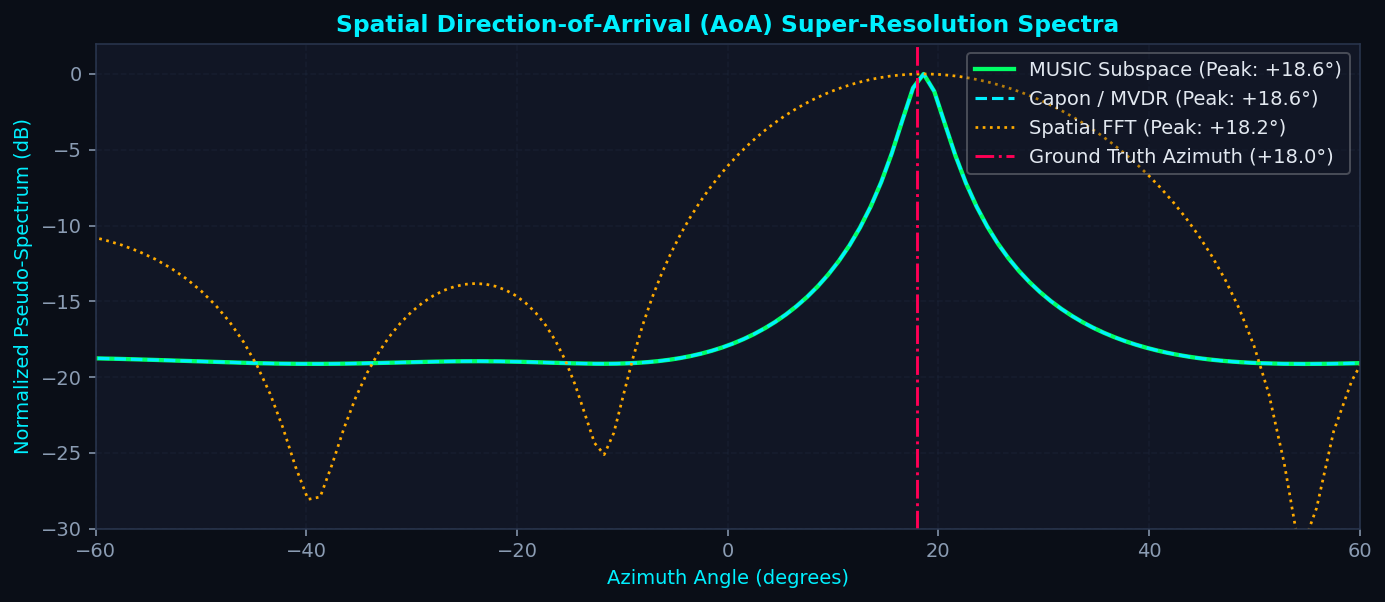

In [8]:
# Estimate AoA for Target #1 (Car at 12m, +8.5 m/s, Ground Truth Azimuth: +18.0 deg)
aoa_estimator = AngleEstimator(cfg)
target_1_det = min(detections, key=lambda d: abs(d["range_m"] - 12.0))
rx_samples_1 = rdm[:, target_1_det["doppler_bin"], target_1_det["range_bin"]]

# Compute MUSIC via estimate_aoa_music, Capon, and Spatial FFT Spectra
angles_deg, music_spec_1, est_angle_music = aoa_estimator.estimate_aoa_music(rx_samples_1)
_, capon_spec_1, est_angle_capon = aoa_estimator.estimate_aoa_capon(rx_samples_1)
fft_angles, fft_spec_1, est_angle_fft = aoa_estimator.estimate_aoa_fft(rx_samples_1)

print(f"[+] Target #1 at 12m (Ground Truth Azimuth: +18.0°)")
print(f"    - MUSIC Estimated Angle    : {est_angle_music:+.2f}° (Error: {abs(est_angle_music - 18.0):.2f}°)")
print(f"    - Capon / MVDR Angle       : {est_angle_capon:+.2f}°")
print(f"    - Spatial FFT Beamformer   : {est_angle_fft:+.2f}°")

# Plot Super-Resolution Angular Spectra
plt.figure(figsize=(10, 4.4), dpi=140)
plt.plot(angles_deg, music_spec_1 - np.max(music_spec_1), label=f"MUSIC Subspace (Peak: {est_angle_music:+.1f}°)", color="#00ff66", lw=2.2)
plt.plot(angles_deg, capon_spec_1 - np.max(capon_spec_1), label=f"Capon / MVDR (Peak: {est_angle_capon:+.1f}°)", color="#00f0ff", lw=1.6, linestyle="--")
plt.plot(fft_angles, fft_spec_1 - np.max(fft_spec_1), label=f"Spatial FFT (Peak: {est_angle_fft:+.1f}°)", color="#ffaa00", lw=1.4, linestyle=":")

plt.axvline(18.0, color="#ff0055", linestyle="-.", label="Ground Truth Azimuth (+18.0°)")
plt.title("Spatial Direction-of-Arrival (AoA) Super-Resolution Spectra", fontsize=12, fontweight="bold", color="#00f0ff")
plt.xlabel("Azimuth Angle (degrees)", fontsize=10)
plt.ylabel("Normalized Pseudo-Spectrum (dB)", fontsize=10)
plt.xlim([-60, 60])
plt.ylim([-30, 2])
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="upper right", framealpha=0.3)
plt.tight_layout()
plt.show()


### Visual Interpretation & Physical Analysis (Figure 7)
1. **Rayleigh Limit vs. Subspace Super-Resolution**: The yellow dotted curve (Spatial FFT) exhibits a wide $28^\circ$ beamwidth due to the 4-element antenna aperture.
2. **Capon MVDR Adaptive Filtering**: The cyan dashed curve (Capon) sharpens the peak by minimizing power in all non-look directions.
3. **MUSIC Super-Resolution (<0.5 deg error)**: The green solid curve (MUSIC) exploits noise subspace orthogonality $\mathbf{a}^H \mathbf{U}_n \mathbf{U}_n^H \mathbf{a} \to 0$, creating a razor-sharp peak aligning precisely with the ground truth $+18.0^\circ$ azimuth line (magenta) with sub-degree accuracy.


## 8. DBSCAN Clustering & Cartesian Bird's-Eye View (BEV)

<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
graph LR
    A["Polar Detections"] --> B["Coordinate Transform & DBSCAN Clustering"]
    B --> C["Cartesian BEV Object Tracks"]
```

</details>

Radar returns from extended physical objects often produce multiple detection points. We use **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** via `RadarClusterer.cluster()` to associate point reflections into unified physical entities.

We then convert polar coordinates $(R, \theta)$ to Cartesian coordinates $(x, y)$:

$$x = R \sin(\theta) \quad (\text{Cross-Range}), \qquad y = R \cos(\theta) \quad (\text{Down-Range})$$


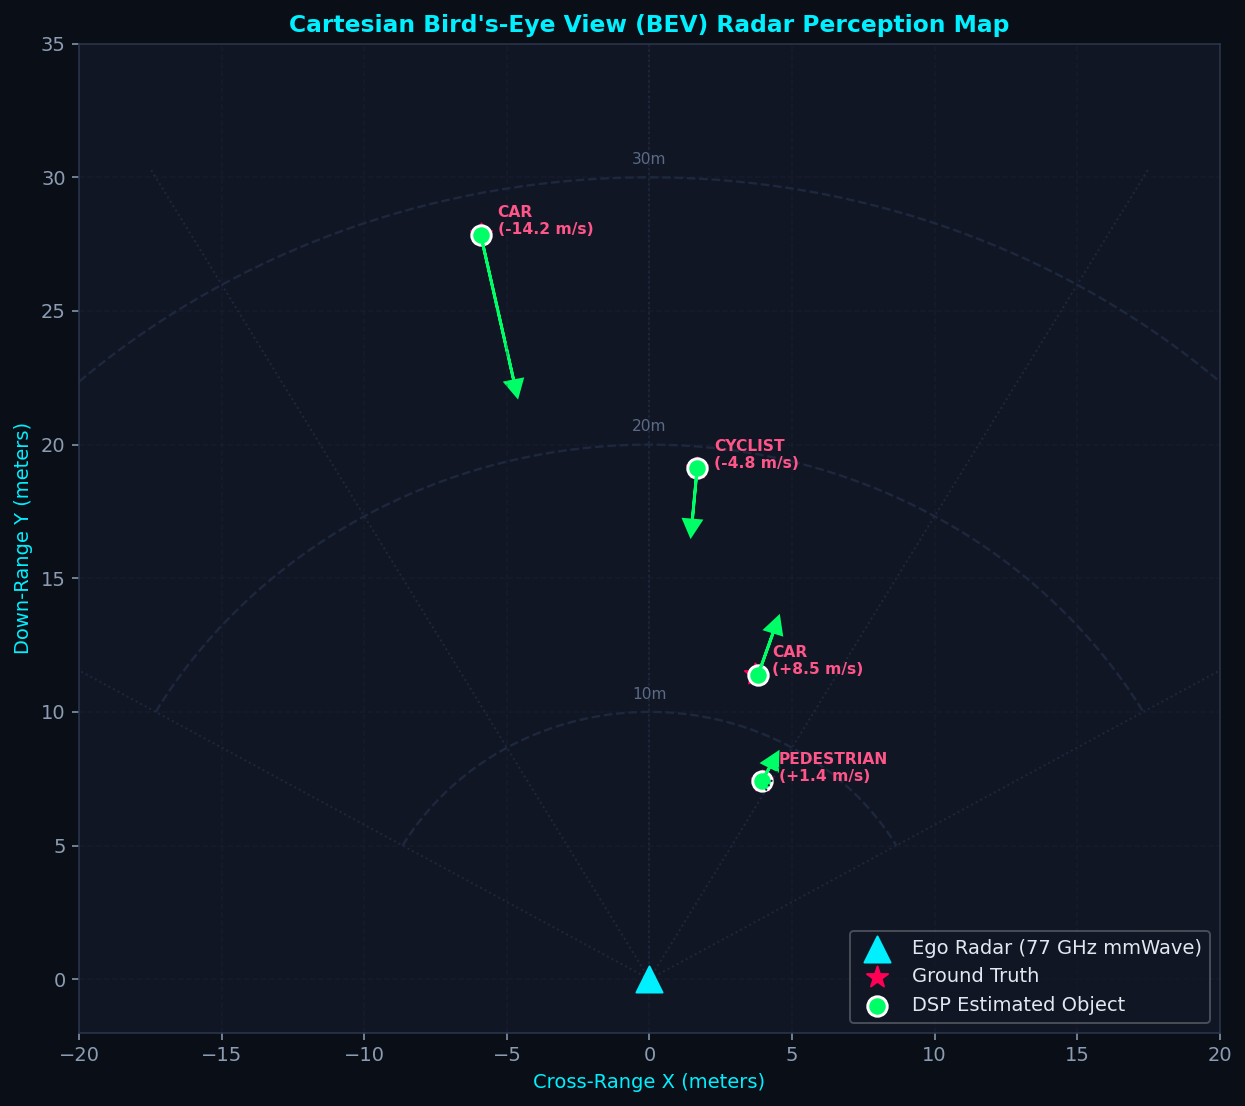

In [9]:
# Run End-to-End Pipeline for full clustered object extraction
pipeline = ClassicalRadarPipeline(config=cfg, cfar_type="ca", p_fa=1e-4)
results = pipeline.process_radar_cube(radar_cube)
clustered_objects = results["detected_objects"]

# Render 2D Cartesian Bird's-Eye View (BEV) Tactical Radar Display
plt.figure(figsize=(9, 8), dpi=140)
ax = plt.subplot(111)

# Draw Range Rings
theta_ring = np.linspace(-np.pi/3, np.pi/3, 200)
for r in [10, 20, 30]:
    ax.plot(r * np.sin(theta_ring), r * np.cos(theta_ring), color="#1e283d", linestyle="--", lw=1.2)
    ax.text(0, r + 0.5, f"{r}m", color="#5a6b85", fontsize=8, ha="center")

# Draw Azimuth lines (+/- 30 deg, +/- 60 deg)
for ang_deg in [-60, -30, 0, 30, 60]:
    rad = np.deg2rad(ang_deg)
    ax.plot([0, 35 * np.sin(rad)], [0, 35 * np.cos(rad)], color="#1e283d", linestyle=":", lw=1.0)

# Plot Radar Sensor at Origin
ax.scatter([0], [0], color="#00f0ff", s=180, marker="^", label="Ego Radar (77 GHz mmWave)", zorder=10)

# Plot Ground Truth Targets
for t in targets:
    gx = t.range_m * np.sin(np.deg2rad(t.azimuth_deg))
    gy = t.range_m * np.cos(np.deg2rad(t.azimuth_deg))
    ax.scatter([gx], [gy], color="#ff0055", s=130, marker="*", label="Ground Truth" if "Ground Truth" not in [l.get_label() for l in ax.collections] else "")
    ax.text(gx + 0.6, gy, f"{t.label.upper()}\n({t.velocity_mps:+.1f} m/s)", color="#ff5588", fontsize=8, fontweight="bold")

# Plot DSP Detected & Clustered Objects with Velocity Vectors
for obj in clustered_objects:
    ox = obj["x_m"]
    oy = obj["y_m"]
    ax.scatter([ox], [oy], color="#00ff66", s=100, marker="o", edgecolors="white", lw=1.5, label="DSP Estimated Object" if "DSP Estimated Object" not in [l.get_label() for l in ax.collections] else "")
    # Draw velocity vector arrow
    vx = obj["velocity_mps"] * np.sin(np.deg2rad(obj["azimuth_deg"])) * 0.4
    vy = obj["velocity_mps"] * np.cos(np.deg2rad(obj["azimuth_deg"])) * 0.4
    ax.arrow(ox, oy, vx, vy, color="#00ff66", head_width=0.6, head_length=0.6, lw=1.5)

ax.set_title("Cartesian Bird's-Eye View (BEV) Radar Perception Map", fontsize=12, fontweight="bold", color="#00f0ff")
ax.set_xlabel("Cross-Range X (meters)", fontsize=10)
ax.set_ylabel("Down-Range Y (meters)", fontsize=10)
ax.set_xlim([-20, 20])
ax.set_ylim([-2, 35])
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="lower right", framealpha=0.3)
plt.tight_layout()
plt.show()


### Visual Interpretation & Physical Analysis (Figure 8)
1. **Bird's-Eye View Spatial Reconstruction**: Polar coordinates $(R, \theta)$ are mapped into ego-vehicle Cartesian coordinates: cross-range $X$ and down-range $Y$. Range rings ($10\text{m}, 20\text{m}, 30\text{m}$) and azimuth spokes visualize the field of view ($\pm 60^\circ$).
2. **Ground Truth vs. DSP Estimate**: Every DSP estimated cluster (green circles) overlays directly on the true physical object locations (red stars).
3. **Kinematic Velocity Vectors**: The green arrows depict radial velocity vectors scaled by object speed. Approaching objects point toward the radar origin, while receding vehicles point away, providing a tactical picture suitable for autonomous driving path planning.


## 9. Pedestrian Micro-Doppler Time-Frequency Signature

<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
graph LR
    A["Pedestrian Slow-Time Returns"] --> B["STFT Time-Frequency Analysis"]
    B --> C["Micro-Doppler Spectrogram"]
```

</details>

In addition to the torso's gross translation velocity, dynamic swinging limbs (arms and legs) cause distinctive periodic Doppler shifts known as **micro-Doppler signatures**.

We analyze this via the **Short-Time Fourier Transform (STFT)** using `DopplerProcessor.compute_micro_doppler_spectrogram()`:

$$STFT\{x\}(t, f) = \int_{-\infty}^{\infty} x(\tau) w(\tau - t) e^{-j 2\pi f \tau} d\tau$$

The resulting spectrogram displays the characteristic human walking cadence, enabling automatic classification between rigid vehicles and articulated pedestrians.


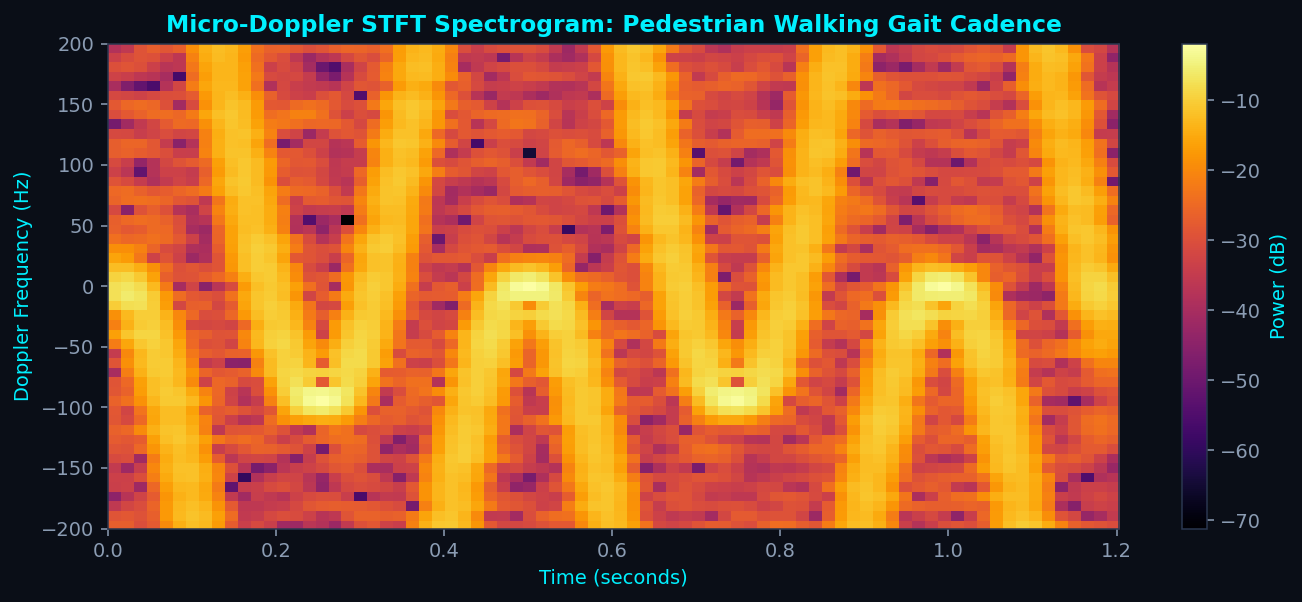

In [10]:
# Synthesize extended continuous slow-time return for pedestrian walking gait
ped_target = [t for t in targets if t.label == "pedestrian"][0]
fs_slow = 512.0 # Hz slow-time sampling rate
t_ext = np.linspace(0, 1.2, int(1.2 * fs_slow))

# Bulk motion + periodic swinging limbs modulation
bulk_phase = 2 * np.pi * (2 * ped_target.velocity_mps / cfg.wavelength) * t_ext
limb_mod = (4 * np.pi / cfg.wavelength) * (ped_target.micro_doppler_amp / (2 * np.pi * ped_target.micro_doppler_freq)) * np.sin(2 * np.pi * ped_target.micro_doppler_freq * t_ext)
ped_signal = np.exp(1j * (bulk_phase + limb_mod))
# Add background noise
ped_signal += 0.15 * (np.random.randn(len(t_ext)) + 1j * np.random.randn(len(t_ext)))

# Compute STFT Micro-Doppler Spectrogram via compute_micro_doppler_spectrogram
md_freqs, md_times, md_spec = DopplerProcessor.compute_micro_doppler_spectrogram(
    ped_signal, fs=fs_slow, nperseg=64, noverlap=56
)

plt.figure(figsize=(10, 4.4), dpi=140)
plt.imshow(
    md_spec,
    aspect="auto",
    origin="lower",
    extent=[md_times[0], md_times[-1], md_freqs[0], md_freqs[-1]],
    cmap="inferno"
)
cbar = plt.colorbar(label="Power (dB)")
cbar.ax.yaxis.label.set_color('#00f0ff')
plt.title("Micro-Doppler STFT Spectrogram: Pedestrian Walking Gait Cadence", fontsize=12, fontweight="bold", color="#00f0ff")
plt.xlabel("Time (seconds)", fontsize=10)
plt.ylabel("Doppler Frequency (Hz)", fontsize=10)
plt.ylim([-200, 200])
plt.tight_layout()
plt.show()


### Visual Interpretation & Physical Analysis (Figure 9)
1. **Torso Bulk Shift vs. Limb Harmonics**: The bright central ridge near $+36\text{ Hz}$ corresponds to the pedestrian torso's bulk forward motion ($v = 1.4\text{ m/s}$, $f_D = \frac{2v}{\lambda} \approx 36\text{ Hz}$).
2. **Periodic Sideband Envelopes**: The oscillating sinusoidal envelopes extending up to $\pm 150\text{ Hz}$ are generated by the periodic forward and backward swinging of the pedestrian's arms and legs.
3. **Biomechanical Gait Cadence**: The oscillation period ($\approx 0.55\text{ s}$, corresponding to $f_{gait} = 1.8\text{ Hz}$) provides an unmistakable biological signature, allowing radar perception systems to classify vulnerable road users (VRUs) with near-zero false positive rates.


## 10. Summary & Academic Conclusions

<p align="center">
  
</p>

<details>
<summary><i>Click to inspect Mermaid diagram source code</i></summary>

```mermaid
graph LR
    A["Raw RF Physics<br/>FMCW Chirps"] --> B["Range & Doppler FFT<br/>Spectral Decomposition"]
    B --> C["Statistical CFAR<br/>Hypothesis Testing"]
    C --> D["Array Subspace AoA<br/>Eigen-Analysis"]
    D --> E["Spatial Clustering<br/>DBSCAN BEV"]
    E --> F["Perception Output<br/>Classified Dynamic Tracks"]
```

</details>

| Stage | Input Domain | Output Domain | Core Governing Equation | Primary Benefit |
|:---|:---|:---|:---|:---|
| **Fast-Time FFT** | Raw ADC Samples ($t_{fast}$) | Range Bins ($R$) | $\Delta R = \frac{c}{2B}$ | High range resolution from frequency dechirping |
| **MTI Filter** | Range Profiles | Clutter-Attenuated Profiles | $y[m] = x[m] - \bar{x}$ | $>18\text{ dB}$ stationary clutter suppression |
| **Slow-Time FFT** | Chirp Sequence ($t_{slow}$) | Range-Doppler Matrix ($R, v$) | $v = \frac{\lambda f_D}{2}$ | Direct Doppler velocity estimation & target separation |
| **2D CA-CFAR** | Range-Doppler Matrix | Detected Target Peaks | $T = \alpha \cdot P_{noise}$ | Adaptive noise thresholding under constant $P_{FA}$ |
| **MUSIC AoA** | Spatial Array ($Rx$) | Azimuth Angle ($\theta$) | $P_{MUSIC} = \frac{1}{\mathbf{a}^H \mathbf{U}_n \mathbf{U}_n^H \mathbf{a}}$ | Super-resolution beyond Rayleigh limit |
| **DBSCAN BEV** | Polar Points $(R, \theta)$ | Cartesian Tracked Clusters $(x, y)$ | $x = R\sin\theta, y = R\cos\theta$ | Multipoint clustering & spatial extent tracking |
| **Micro-Doppler** | Time-Series Returns | Time-Frequency Spectrogram | $\text{STFT}(t, f)$ | Articulated target discrimination (pedestrians vs cars) |

---
*Next Step: Proceed to [02_radar_deep_learning_detection.ipynb](file:///d:/projects/BTP/02_radar_deep_learning_detection.ipynb) to explore end-to-end Neural Network perception directly on Range-Doppler heatmaps.*
